# Research Question Tests

Thesis: *Experimental Setup*, section *Analysis of the Research Questions*, and *Results*, sections *Generic Masculine against Neutral Term*, *Dominance across Language Forms* and *Interaction of Language Form and Gender Form*. The exports also feed the tables of *The Output-Level Classification* and of the entanglement sections.

**Requirements**
- Environment: `easy-language` (`environment-easy-language.yml`)
- Packages: pandas, scipy, numpy, matplotlib, seaborn
- Data: `data/main_run/mivolo_results.csv`, `entanglement_scores.csv`, `word_shares_long.csv`, `dominance_results.csv` (in this repository)
- GPU and network: not needed

**Writes:** `exports/dominance_scores.csv`, `exports/rq_*.csv`, `exports/rq1_*.csv`, `figures/contrast-{lexis,languageform,interaction}.pdf`

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "corpus").is_dir())
os.chdir(ROOT)
for folder in ("corpus", "measurement"):
    sys.path.insert(0, str(ROOT / "src" / folder))

import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

import corpus_spec
from dominance import DOM_BLOCKS, ENT_BLOCKS, GM, NT, dominance, load_readout
from IPython.display import display

GSL_COLOUR, GAL_COLOUR = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#9c9b95"

## The analysis

The tests of the research questions as tab:analysis fixes them: one value per scene, paired t-test with 95 % confidence interval and Wilcoxon test alongside, at the primary block and its replication. The keys `rq2` to `rq4` follow `rq_tests.csv`, not the reordered numbering of the thesis.

In [2]:
FORMS = corpus_spec.GENDER_FORMS
VARIETIES = ("ls", "sd")                      # GAL, GSL
LOCALISATION_BLOCKS = [f"single_{i}" for i in range(11)]


def scene_cells(df: pd.DataFrame, value: str) -> pd.DataFrame:
    """Seed mean per scene, language form and gender form, one column per (variety, condition)."""
    cells = df.groupby(["profession", "scene_label", "variety", "condition"])[value].mean()
    return cells.unstack(["variety", "condition"])


def complete(table: pd.DataFrame, cells: list[tuple]) -> pd.DataFrame:
    """Scenes in which every contrasted cell keeps at least one image."""
    return table[cells].dropna()


def paired(diffs: pd.Series) -> dict:
    n = len(diffs)
    mean, sd = diffs.mean(), diffs.std(ddof=1)
    half = stats.t.ppf(0.975, n - 1) * sd / math.sqrt(n)
    t = stats.ttest_1samp(diffs, 0.0)
    w = stats.wilcoxon(diffs)
    return {"n_scenes": n, "mean": round(mean, 4), "ci_low": round(mean - half, 4),
            "ci_high": round(mean + half, 4), "t": round(t.statistic, 3),
            "p_t": round(t.pvalue, 4), "wilcoxon_W": round(w.statistic, 1),
            "p_wilcoxon": round(w.pvalue, 4)}


def rq2(dom: pd.DataFrame) -> list[dict]:
    out = []
    for block, role in zip(DOM_BLOCKS, ("primary", "replication")):
        table = scene_cells(dom[dom["layer_idx"] == block], "D")
        for label, forms in (("all four gender forms", FORMS),
                             ("without the typographical form", FORMS[:3])):
            cells = [(v, c) for v in VARIETIES for c in forms]
            t = complete(table, cells)
            diffs = t[[("ls", c) for c in forms]].mean(axis=1) - t[[("sd", c) for c in forms]].mean(axis=1)
            out.append({"question": "RQ2", "block": f"dual_{block}", "role": role,
                        "variant": label, "contrast": "GAL minus GSL", **paired(diffs)})
    return out


def rq3_rq4(ent: pd.DataFrame) -> list[dict]:
    out = []
    for block, role in zip(ENT_BLOCKS, ("primary", "replication")):
        table = scene_cells(ent[ent["layer"] == block], "score")
        t = complete(table, [(v, c) for v in VARIETIES for c in (GM, NT)])
        gap = {v: t[(v, GM)] - t[(v, NT)] for v in VARIETIES}
        out.append({"question": "RQ3", "block": block, "role": role, "variant": "",
                    "contrast": "generic masculine minus neutral term, mean of both language forms",
                    **paired((gap["ls"] + gap["sd"]) / 2)})
        out.append({"question": "RQ4", "block": block, "role": role, "variant": "",
                    "contrast": "(generic masculine minus neutral term) in GAL minus the same in GSL",
                    **paired(gap["ls"] - gap["sd"])})
    return out


def gender_forms_on_test_scenes(ent: pd.DataFrame) -> pd.DataFrame:
    """The four gender forms on the scenes the RQ3 and RQ4 tests use, those anchored in both language
    forms, so that the levels add up to the tested contrast.
    """
    rows = []
    for block in ENT_BLOCKS:
        table = scene_cells(ent[ent["layer"] == block], "score")
        t = table.loc[complete(table, [(v, c) for v in VARIETIES for c in (GM, NT)]).index]
        series = {c: (t[("ls", c)], t[("sd", c)]) for c in FORMS}
        series["generic_masc_minus_neutral_term"] = (t[("ls", GM)] - t[("ls", NT)],
                                                     t[("sd", GM)] - t[("sd", NT)])
        for condition, (ls, sd) in series.items():
            both = pd.concat([ls, sd], axis=1).dropna()
            rows.append({"block": block, "condition": condition, "n_scenes": len(both),
                         "mean_score_ls": round(both.iloc[:, 0].mean(), 4),
                         "mean_score_sd": round(both.iloc[:, 1].mean(), 4),
                         "mean_score_both": round(both.mean(axis=1).mean(), 4)})
    return pd.DataFrame(rows)


def profession_means(ent: pd.DataFrame, block: str, condition: str) -> pd.DataFrame:
    sub = ent[(ent["layer"] == block) & (ent["condition"] == condition)]
    per_scene = sub.groupby(["profession", "scene_label", "variety"])["score"].mean()
    return per_scene.groupby(["profession", "variety"]).agg(["mean", "count"]).reset_index()


def rq1_coupling(ent: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for block in ENT_BLOCKS:
        pm = profession_means(ent, block, NT)
        for _, r in pm.iterrows():
            rows.append({"block": block, "profession": r["profession"], "variety": r["variety"],
                         "stereotype_direction": corpus_spec.PROFESSIONS[r["profession"]],
                         "misersky_share_women": corpus_spec.STEREO_VALUE_DE[r["profession"]],
                         "mean_score_neutral_term": round(r["mean"], 4), "n_scenes": int(r["count"])})
    return pd.DataFrame(rows).sort_values(["block", "variety", "misersky_share_women"])


def rq1_localisation(ent: pd.DataFrame, scores_all: pd.DataFrame) -> pd.DataFrame:
    """The profile over blocks 0 to 10, and for every block the number of anchored scenes whose anchors
    are out of order, which is what bounds the profile at block 10.
    """
    gaps = (scores_all.dropna(subset=["anchor_gap"])
            .drop_duplicates(["layer", "variety", "profession", "scene_label"]))
    rows = []
    for i in range(20):
        block = f"single_{i}"
        pm = profession_means(ent, block, NT) if block in LOCALISATION_BLOCKS else None
        for v in VARIETIES:
            g = gaps[(gaps["layer"] == block) & (gaps["variety"] == v)]
            row = {"block": block, "variety": v, "scenes_anchored": len(g),
                   "scenes_out_of_order": int((g["anchor_gap"] <= 0).sum())}
            if pm is not None:
                p = pm[pm["variety"] == v].assign(
                    direction=lambda d: d["profession"].map(corpus_spec.PROFESSIONS)
                ).groupby("direction")["mean"].mean()
                row.update({"male_stereotyped": round(p["male"], 4),
                            "contested": round(p["contested"], 4),
                            "female_stereotyped": round(p["female"], 4),
                            "separation_male_minus_female": round(p["male"] - p["female"], 4)})
            rows.append(row)
    return pd.DataFrame(rows)


def rq1_correspondence(ent: pd.DataFrame, readout: pd.DataFrame) -> tuple[pd.DataFrame, list[dict]]:
    faces = readout[readout["face"]]
    share = (faces.assign(male=faces["gender"] == "male")
             .groupby(["profession", "condition", "variety"])["male"].mean())
    cells, tests = [], []
    for block in ENT_BLOCKS:
        sub = ent[(ent["layer"] == block) & ent["image_id"].isin(set(faces["image_id"]))]
        per_scene = sub.groupby(["profession", "scene_label", "condition", "variety"])["score"].mean()
        a = per_scene.groupby(["profession", "condition", "variety"]).mean()
        joined = pd.concat({"mean_score": a, "share_male": share}, axis=1).dropna().reset_index()
        joined["block"] = block
        cells.append(joined)
        for v in VARIETIES:
            j = joined[joined["variety"] == v]
            rho = stats.spearmanr(j["mean_score"], j["share_male"])
            tests.append({"block": block, "variety": v, "n_cells": len(j),
                          "spearman_rho": round(rho.statistic, 4)})
    return pd.concat(cells), tests

In [3]:
RUN_DIR = Path("data/main_run")
OUT_DIR = Path("exports")

readout = load_readout(RUN_DIR)
single = readout[readout["readout_status"] == "single"]
keep = set(single["image_id"])

excl = (readout.assign(excluded=readout["readout_status"] != "single",
                       no_face=(readout["readout_status"] == "single") & ~readout["face"])
        .groupby(["variety", "condition"])
        .agg(n=("image_id", "size"), single=("readout_status", lambda s: (s == "single").sum()),
             multiple=("readout_status", lambda s: (s == "multiple").sum()),
             none=("readout_status", lambda s: (s == "none").sum()),
             single_without_face=("no_face", "sum"))
        .reset_index())
excl.to_csv(OUT_DIR / "rq_exclusions.csv", index=False)
labelled = single[single["face"]]
(labelled.assign(male=labelled["gender"] == "male")
 .groupby(["profession", "condition", "variety"])["male"].agg(["mean", "size"])
 .rename(columns={"mean": "share_male", "size": "n_images"}).round(4).reset_index()
 .to_csv(OUT_DIR / "rq_depicted_gender.csv", index=False))

In [4]:
scores_all = pd.read_csv(RUN_DIR / "entanglement_scores.csv")
ent = scores_all[scores_all["image_id"].isin(keep)].dropna(subset=["score"])

dom = dominance(RUN_DIR, keep, readout)
dom = dom.merge(single[["image_id", "profession", "scene_label", "condition", "variety", "seed"]],
                on="image_id")
dom.round(8).to_csv(OUT_DIR / "dominance_scores.csv", index=False)

tests = pd.DataFrame(rq2(dom) + rq3_rq4(ent))
tests.to_csv(OUT_DIR / "rq_tests.csv", index=False)
gender_forms_on_test_scenes(ent).to_csv(OUT_DIR / "rq_gender_forms_test_scenes.csv", index=False)
rq1_coupling(ent).to_csv(OUT_DIR / "rq1_coupling.csv", index=False)
rq1_localisation(ent, scores_all).to_csv(OUT_DIR / "rq1_localisation.csv", index=False)
corr_cells, corr = rq1_correspondence(ent, readout)
corr_cells.round(4).to_csv(OUT_DIR / "rq1_correspondence_cells.csv", index=False)
pd.DataFrame(corr).to_csv(OUT_DIR / "rq1_correspondence.csv", index=False)

In [5]:
print(f"{len(keep)} of {len(readout)} test images depict exactly one person; "
      f"{dom['image_id'].nunique()} carry a dominance value, "
      f"{ent['image_id'].nunique()} an entanglement score")
display(tests)
display(pd.DataFrame(corr))
print(f"\nwritten to {OUT_DIR}: rq_exclusions, rq_depicted_gender, rq_tests, "
      f"rq_gender_forms_test_scenes, rq1_coupling, rq1_localisation, rq1_correspondence(_cells); "
      f"and dominance_scores")

1173 of 1440 test images depict exactly one person; 1102 carry a dominance value, 1112 an entanglement score


,question,block,role,variant,contrast,n_scenes,mean,ci_low,ci_high,t,p_t,wilcoxon_W,p_wilcoxon
0,RQ2,dual_2,primary,all four gender forms,GAL minus GSL,32,-0.0066,-0.0348,0.0216,-0.476,0.6373,259.0,0.9339
1,RQ2,dual_2,primary,without the typographical form,GAL minus GSL,32,-0.0033,-0.0311,0.0245,-0.242,0.8103,261.0,0.9632
2,RQ2,dual_4,replication,all four gender forms,GAL minus GSL,32,0.0236,-0.0253,0.0724,0.984,0.3326,230.0,0.5361
3,RQ2,dual_4,replication,without the typographical form,GAL minus GSL,32,0.0295,-0.0171,0.0762,1.292,0.2060,196.0,0.2100
4,RQ3,single_4,primary,,"generic masculine minus neutral term, mean of ...",31,0.3352,0.2327,0.4376,6.680,0.0000,19.0,0.0000
5,RQ4,single_4,primary,,(generic masculine minus neutral term) in GAL ...,31,0.0204,-0.0592,0.0999,0.523,0.6048,221.0,0.6083
6,RQ3,single_5,replication,,"generic masculine minus neutral term, mean of ...",31,0.3068,0.2123,0.4014,6.626,0.0000,15.0,0.0000
7,RQ4,single_5,replication,,(generic masculine minus neutral term) in GAL ...,31,0.0331,-0.0440,0.1101,0.877,0.3876,202.0,0.3777


,block,variety,n_cells,spearman_rho
0,single_4,ls,24,0.9227
1,single_4,sd,24,0.9161
2,single_5,ls,24,0.9214
3,single_5,sd,24,0.9036



written to exports: rq_exclusions, rq_depicted_gender, rq_tests, rq_gender_forms_test_scenes, rq1_coupling, rq1_localisation, rq1_correspondence(_cells); and dominance_scores


## The paired contrasts

The scene-wise differences each test is computed on, with the 95 % confidence interval of the primary block and of its replication.

In [6]:
READOUT = RUN_DIR / "mivolo_results.csv"
EXPORT = Path("exports/rq_tests.csv")


QUESTIONS = {
    "rq2": {"name": "languageform", "blocks": ("dual_2", "dual_4"), "sign_is_language_form": True,
            "axis": "Dominance D, GAL minus GSL"},
    "rq3": {"name": "lexis", "blocks": ("single_4", "single_5"), "sign_is_language_form": False,
            "axis": "Entanglement score, generic masculine minus neutral term"},
    "rq4": {"name": "interaction", "blocks": ("single_4", "single_5"), "sign_is_language_form": True,
            "axis": "Contrast in GAL minus the same contrast in GSL"},
}


def eligible_scores() -> pd.DataFrame:
    """The entanglement scores of the images that depict exactly one person."""
    readout = pd.read_csv(READOUT)
    keep = set(readout[readout["readout_status"] == "single"]["image_id"])
    scores = pd.read_csv(RUN_DIR / "entanglement_scores.csv")
    return scores[scores["image_id"].isin(keep)].dropna(subset=["score"])


def differences(question: str, block: str) -> pd.Series:
    """One difference per scene, formed as the analysis above forms it."""
    if question == "rq2":
        dom = pd.read_csv("exports/dominance_scores.csv")
        table = scene_cells(dom[dom["layer_idx"] == int(block.split("_")[1])], "D")
        cells = [(v, c) for v in VARIETIES for c in FORMS]
        t = table[cells].dropna()
        return (t[[("ls", c) for c in FORMS]].mean(axis=1)
                - t[[("sd", c) for c in FORMS]].mean(axis=1))

    ent = eligible_scores()
    table = scene_cells(ent[ent["layer"] == block], "score")
    t = table[[(v, c) for v in VARIETIES for c in (GM, NT)]].dropna()
    gap = {v: t[(v, GM)] - t[(v, NT)] for v in VARIETIES}
    return (gap["ls"] + gap["sd"]) / 2 if question == "rq3" else gap["ls"] - gap["sd"]


def interval(diffs: pd.Series) -> tuple[float, float, float]:
    half = stats.t.ppf(0.975, len(diffs) - 1) * diffs.std(ddof=1) / math.sqrt(len(diffs))
    return diffs.mean(), diffs.mean() - half, diffs.mean() + half


def plot_contrast(question: str, out_path: Path) -> None:
    sns.set_theme(style="whitegrid")
    plt.rcParams.update({
        "font.size": 8, "axes.labelsize": 8.5, "xtick.labelsize": 8, "ytick.labelsize": 8,
    })
    blocks = QUESTIONS[question]["blocks"]
    fig, ax = plt.subplots(figsize=(5.8, 1.7), layout="constrained")
    rng = np.random.default_rng(0)

    rows = {blocks[0]: 1.0, blocks[1]: 0.0}
    per_block = {b: differences(question, b) for b in blocks}
    span = max(abs(d).max() for d in per_block.values()) * 1.15

    if QUESTIONS[question]["sign_is_language_form"]:
        for side, colour, label in ((1, GAL_COLOUR, "GAL larger →"), (-1, GSL_COLOUR, "← GSL larger")):
            ax.annotate(label, (0.5 + side * 0.5, 1.06), xycoords="axes fraction", fontsize=7,
                        color=colour, ha="right" if side > 0 else "left", annotation_clip=False)
    ax.axvline(0, color=INK, lw=0.9, zorder=2)

    labels = []
    for (block, y), role in zip(rows.items(), ("primary", "replication")):
        diffs = per_block[block]
        mean, low, high = interval(diffs)
        ax.plot(diffs.values, y + rng.uniform(-0.17, 0.17, len(diffs)), "o", color=INK,
                markersize=2.6, markeredgewidth=0, alpha=0.35, linestyle="none", zorder=3)
        ax.plot([low, high], [y, y], "-", color=MUTED, lw=3.2, solid_capstyle="round", zorder=4)
        ax.plot([mean], [y], "D", color=INK, markersize=4.5, markeredgecolor="white",
                markeredgewidth=0.9, zorder=5)
        labels.append(f"{block.replace('_', ' ')}, {role}\n"
                      f"({int((diffs > 0).sum())} of {len(diffs)} above zero)")

    ax.set_yticks(list(rows.values()), labels)
    ax.set_ylim(-0.55, 1.55)
    ax.set_xlim(-span, span)
    ax.tick_params(axis="y", length=0)
    ax.xaxis.grid(True, color=GRID, lw=0.5, alpha=0.5)
    ax.yaxis.grid(False)
    ax.set_xlabel(QUESTIONS[question]["axis"], color=INK)
    sns.despine(ax=ax, left=True, bottom=True)
    fig.get_layout_engine().set(w_pad=0.06, h_pad=0.04)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, bbox_inches="tight")
    print(f"-> {out_path}")


def report_contrast(question: str) -> None:
    """The numbers the section quotes, against the export the analysis wrote."""
    export = pd.read_csv(EXPORT)
    export = export[export["question"] == question.upper()]
    for block in QUESTIONS[question]["blocks"]:
        diffs = differences(question, block)
        mean, low, high = interval(diffs)
        print(f"{block}: n = {len(diffs)}, mean {mean:+.4f}, 95 % CI [{low:+.4f}, {high:+.4f}], "
              f"positive in {int((diffs > 0).sum())} of {len(diffs)} scenes")
        row = export[(export["block"] == block)]
        if question == "rq2":
            row = row[row["variant"] == "all four gender forms"]
        if len(row):
            drift = abs(row.iloc[0]["mean"] - round(mean, 4))
            print(f"          deviation from {EXPORT}: {drift:.4f}")
            assert drift < 1e-4, drift

### Generic masculine against neutral term

The generic masculine lies closer to the male anchor by 0.335 of the anchor distance, 95 % CI [0.233, 0.438], and scores higher in 28 of 31 scenes.

single_4: n = 31, mean +0.3352, 95 % CI [+0.2327, +0.4376], positive in 28 of 31 scenes
          deviation from exports/rq_tests.csv: 0.0000
single_5: n = 31, mean +0.3068, 95 % CI [+0.2123, +0.4014], positive in 29 of 31 scenes
          deviation from exports/rq_tests.csv: 0.0000


-> figures/contrast-lexis.pdf


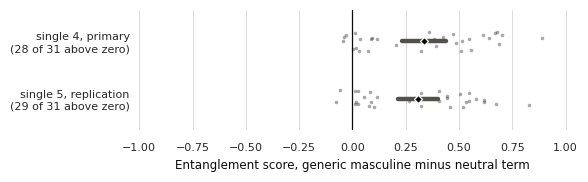

In [7]:
report_contrast("rq3")
plot_contrast("rq3", Path(f"figures/contrast-{QUESTIONS['rq3']['name']}.pdf"))

### Dominance across language forms

No significant difference in dominance between the language forms: −0.007, 95 % CI [−0.035, 0.022], p = 0.64.

dual_2: n = 32, mean -0.0066, 95 % CI [-0.0348, +0.0216], positive in 16 of 32 scenes
          deviation from exports/rq_tests.csv: 0.0000
dual_4: n = 32, mean +0.0236, 95 % CI [-0.0253, +0.0724], positive in 16 of 32 scenes
          deviation from exports/rq_tests.csv: 0.0000


-> figures/contrast-languageform.pdf


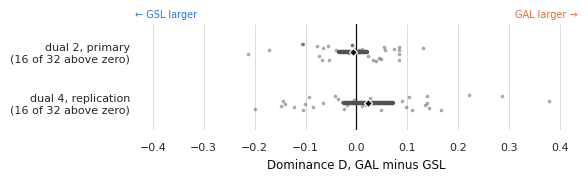

In [8]:
report_contrast("rq2")
plot_contrast("rq2", Path(f"figures/contrast-{QUESTIONS['rq2']['name']}.pdf"))

### Interaction of language form and gender form

No significant difference between the language forms in the lexical contrast: 0.020, 95 % CI [−0.059, 0.100], p = 0.60.

single_4: n = 31, mean +0.0204, 95 % CI [-0.0592, +0.0999], positive in 18 of 31 scenes
          deviation from exports/rq_tests.csv: 0.0000
single_5: n = 31, mean +0.0331, 95 % CI [-0.0440, +0.1101], positive in 18 of 31 scenes
          deviation from exports/rq_tests.csv: 0.0000


-> figures/contrast-interaction.pdf


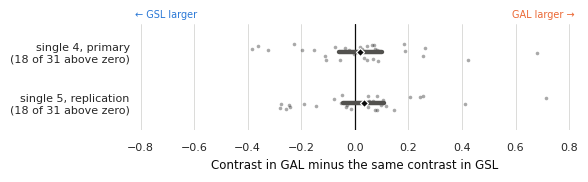

In [9]:
report_contrast("rq4")
plot_contrast("rq4", Path(f"figures/contrast-{QUESTIONS['rq4']['name']}.pdf"))